<!-- File automatically generated using DocOnce (https://github.com/doconce/doconce/):
doconce format ipynb 37.samkoding-notebook.do.txt --userdef_environment_file=../userdef_environments.py --skip_inline_comments --encoding=utf-8 --language=Norwegian --ipynb_disable_mpl_inline --execute=abort --output=../../pub/37/37.samkoding.ipynb --execute -->

# BIOS1101 H26 Samkoding

Date: **Uke 37**

# Samkoding uke 37

Til studentene: dette er 'oppskriften' til samkodingsgruppe denne uken.
Undervisere bruker denne noen ganger nøyaktig når de underviser,
noen ganger avviker de fra den.
Stoffet i notebooken ansees å være en del av pensum.

Vi legger disse notebooks ut til dere for at dere kan studere stoffet på egenhånd,
eventuelt sammen med opptak av gruppetimene.

Dette er en Jupyter Notebook, som betyr at all kode kan kjøres av dere,
men i tillegg kan dere legge til kodeceller for å skrive deres egen kode.
Brukt på denne måten kan det føre til økt læring!

------

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Ukens samkoding

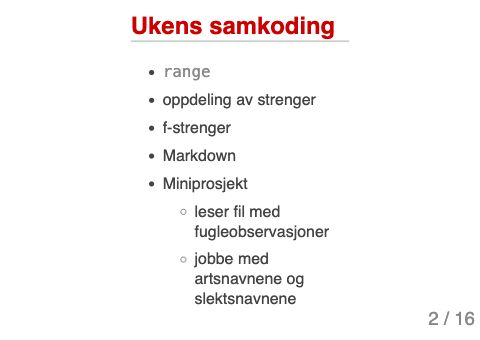

</div>

I dag bygger vi et lite miniprosjekt der vi leser en feltfil med fugleobservasjoner,
plukker ut artsnavnene og avslutter med en enkel analyse av slektsnavnene i dataene.

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* range

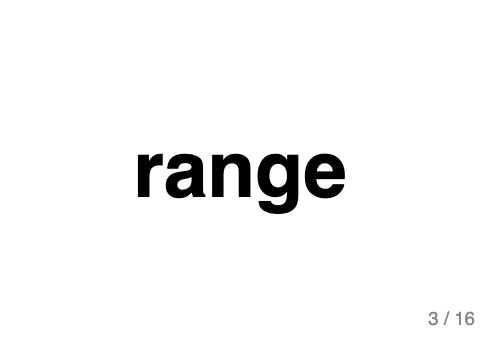

</div>

## Miniprosjekt: artsobservasjoner

I dag skal vi jobbe med en liten feltfil med fugleobservasjoner.
Hver rad i filen inneholder en tekststreng med norsk og latinsk artsnavn,
samt hvor mange individer som ble sett i den observasjonen.

Vi starter med å lese filen og se på innholdet:

In [2]:
import pandas as pd

data = pd.read_csv("species_observations.csv")
print(data)

                                  fugl  antall        sted
0       Rødvingetrost (Turdus iliacus)       3    Nordmyra
1            Gråtrost (Turdus pilaris)       5    Nordmyra
2        Blåmeis (Cyanistes caeruleus)       2  Bjørkelund
3           Svarttrost (Turdus merula)       1   Engkanten
4          Bokfink (Fringilla coelebs)       4  Bjørkelund
5              Kjøttmeis (Parus major)       2   Engkanten
6       Rødstrupe (Erithacus rubecula)       1  Bekkedalen
7  Gransanger (Phylloscopus collybita)       2  Bekkedalen


Vi ser at Rødvingetrost, *Turdus iliacus* har 'Turdus' til sammen med
Gråtrost, *Turdus pilaris*.
Latinske navn består vanligvis av slektsnavn ('genus') 
etterfulgt av artsnaven ('species').

Spørsmålet vi skal prøve å svare på er:
"Hvor stor andel av observasjonene er fugl av slekten (genus) `Turdus`?"

For å komme fram til svaret må vi etter hvert rense tekststrengene i kolonnen `fugl`,
men først trenger vi en enkel måte å nummerere observasjonene på.
Det er en typisk jobb for `range()`.

In [3]:
fugler = list(data["fugl"])
antall = list(data["antall"])
steder = list(data["sted"])

print(fugler)
print(antall)

['Rødvingetrost (Turdus iliacus)', 'Gråtrost (Turdus pilaris)', 'Blåmeis (Cyanistes caeruleus)', 'Svarttrost (Turdus merula)', 'Bokfink (Fringilla coelebs)', 'Kjøttmeis (Parus major)', 'Rødstrupe (Erithacus rubecula)', 'Gransanger (Phylloscopus collybita)']
[3, 5, 2, 1, 4, 2, 1, 2]


Hvis vi ønsker observasjonsnummer `1, 2, 3, ...` kan vi lage listen med en while løkke:

In [4]:
observasjonsnumre = []
indeks = 1
while indeks <= len(antall):
  observasjonsnumre.append(indeks)
  indeks = indeks + 1

print(observasjonsnumre)

[1, 2, 3, 4, 5, 6, 7, 8]


`range()` gjør den samme jobben mye enklere:

In [5]:
R = range(1, len(antall) + 1)
L = list(R)
print(L)

[1, 2, 3, 4, 5, 6, 7, 8]


<div class="alert alert-block alert-info">
Vis dette med hjelp av <a href="https://pythontutor.com/python-compiler.html#mode=edit">pythontutor.com</a>.
Bruk <code>R = range(1, 9)</code>
</div>

In [6]:
R = range(1, len(antall) + 1)
L = list(R)
print(L)

Legg merke til at vi trenger å konvertere `R` til en liste med hjelp av `list()`
når vi vil skrive ut tallene.
Hvis vi ikke gjør det får vi bare vite at `R` er en range:

In [6]:
R = range(1, len(antall) + 1)
print(R)
print(type(R))
L = list(R)
print(type(L))

range(1, 9)
<class 'range'>
<class 'list'>


Den enkle forklaringen er at `range()` ikke 'produserer' selve tallene direkte,
bare når de er 'nødvendige'. Dette sparer potensielt tid og dataminne.
Å konvertere dem til en liste gir de faktiske tallene.

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* `range()`

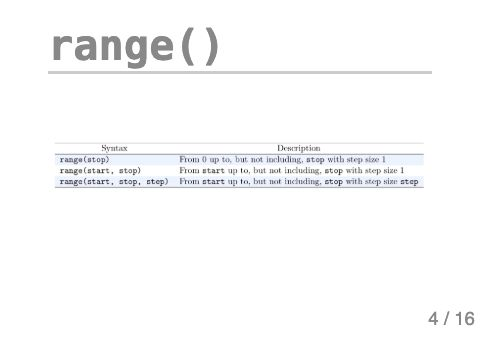

</div>

Den fulle syntaksen til range er

        range(start, stop, step)


Som betyr "From `start` up to, but not including, `stop` with step size `step`"

Eksempler fra observasjonsfilen:

* de første fem observasjonsnumrene

In [7]:
print(list(range(1, 6)))

[1, 2, 3, 4, 5]


* annenhver observasjon fra og med observasjon 2 til og med observasjon 8

In [8]:
print(list(range(2, 9, 2)))

[2, 4, 6, 8]


* telle ned observasjonsnumrene fra 8 til 1

In [9]:
print(list(range(8, 0, -1)))

[8, 7, 6, 5, 4, 3, 2, 1]


Merk at tallene for `start`, `stop` *og* `step` må være av type `int`:

In [10]:
print(list(range(1.0, 8, 1)))

TypeError: 'float' object cannot be interpreted as an integer

In [11]:
print(list(range(1, 8, 1.5)))

TypeError: 'float' object cannot be interpreted as an integer

Senere i kurset lærer vi om en variant av `range`
som lar oss bruke `float` verdier.

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Oppgave: observasjonsnumre

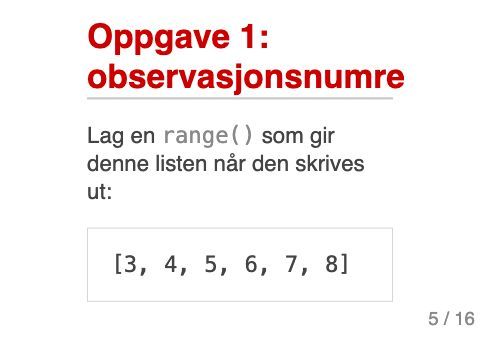

</div>

## Bruk av range med plotting
En fin måte å bruke `range()` er når man skal plotte ting.
Her vil vi plotte hvor mange individer som ble sett i hver observasjon.

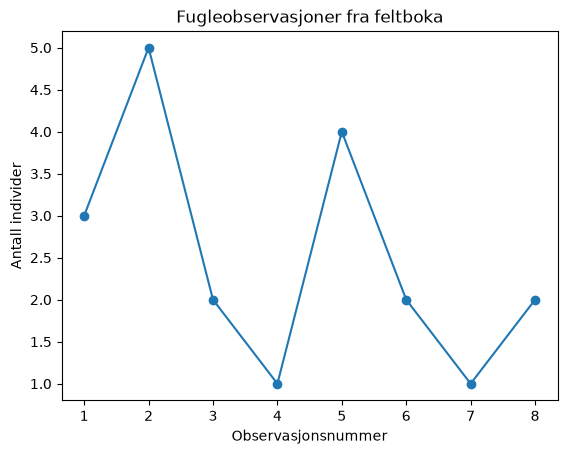

In [12]:
observasjonsnumre = range(1, len(antall) + 1)

import matplotlib.pyplot as plt

plt.plot(observasjonsnumre, antall, "o-")
plt.xlabel("Observasjonsnummer")
plt.ylabel("Antall individer")
plt.title("Fugleobservasjoner fra feltboka")
plt.show()

Her er `antall` en liste over verdiene vi vil plotte på y-aksen,
mens `range()` lager tallene `1, 2, 3, ...` til x-aksen.
I plotting kan vi bruke en `range()` direkte uten å gjøre den om til en liste først.

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* `range()` versus liste
* Oppdeling av strenger

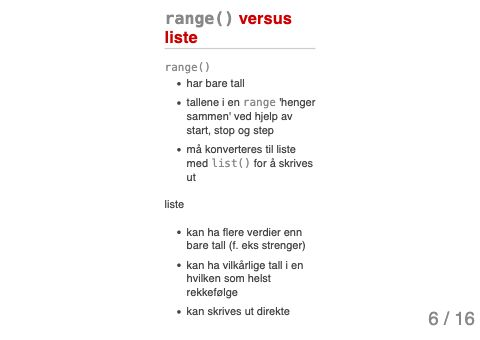

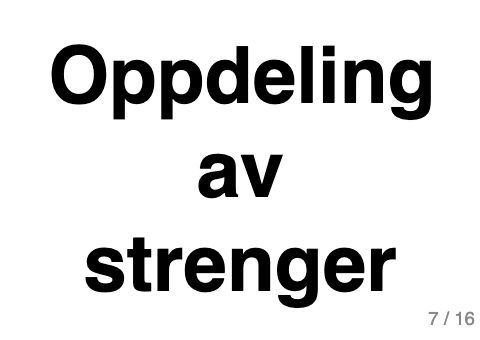

</div>

Vi har nå lest inn en fil der artsnavnene ligger som tekststrenger.

For å tilgang til slektsnavnet trenger vi å delle opp artsnavnet:

In [13]:
print(fugler[0])

Rødvingetrost (Turdus iliacus)


vi ønsker å få dette delt opp i `Rødvingetrost`,
`Turdus` og `iliacus`

Python bruker samme oppdelingssyntaks for strenger som for lister.

Vi starter med en liste av bokstaver:

In [14]:
bokstaver = ["R", "ø", "d", "v", "i", "n", "g", "e", "t", "r", "o", "s", "t"]
print(bokstaver)

['R', 'ø', 'd', 'v', 'i', 'n', 'g', 'e', 't', 'r', 'o', 's', 't']


Hvis vi ønsker å selektere bokstavene som danner `"trost"` gjør vi:

In [15]:
print(bokstaver[8:13])

['t', 'r', 'o', 's', 't']


Når vi bruker en streng variabel kan vi faktisk gjøre det samme:

In [16]:
tekst = fugler[0]
print(tekst)

Rødvingetrost (Turdus iliacus)


In [17]:
print(tekst[8:13])

trost


Vi kan også prøve å hente ut hele det norske og latinske navnet
ved hjelp av faste posisjoner:

In [18]:
norsk_navn = tekst[:13]
latinsk_navn = tekst[15:-1]

print(norsk_navn)
print(latinsk_navn)

Rødvingetrost
Turdus iliacus


Dette er en første løsning som faktisk virker for denne ene observasjonen.
Men den er litt sårbar, fordi den bygger på at vi kjenner posisjonene nøyaktig.

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Oppgave: selektere fra en streng

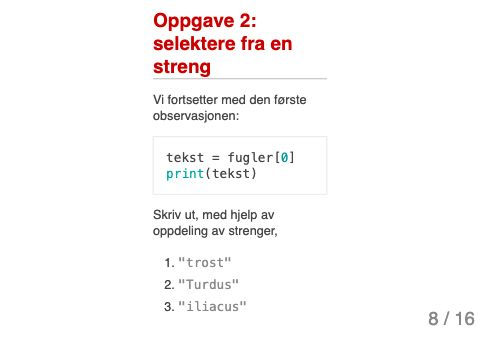

</div>

Vi ser at oppdeling av strenger fungerer på samme måte som med lister.
Negative indekser er ofte nyttige når vi vil telle fra slutten av strengen.

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Oppgave: selektere fra en streng 2

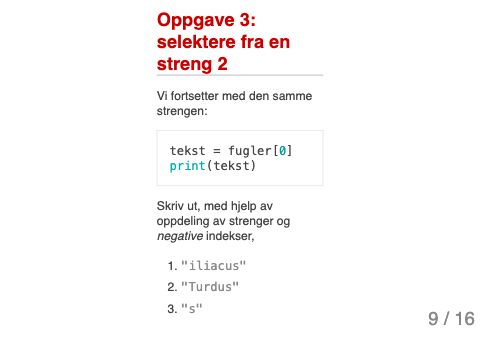

</div>

### Endring av strenger

Med en liste er det mulig å bytte ut eksisterende verdier, for eksempel:

In [19]:
tall = [1, 2, 3, 4]
print(tall)
print(tall[0])
tall[0] = 0
print(tall[0])
print(tall)

[1, 2, 3, 4]
1
0
[0, 2, 3, 4]


Men når vi prøver det med strenger får vi en feilmelding:

In [20]:
hilsen = "hallo"
print(hilsen[0])
hilsen[0] = 'H'

h


TypeError: 'str' object does not support item assignment

En streng kan ikke endres, den er såkalt *immutable*.
Hvis vi ønsker en annen tekst må vi lage en ny streng,
for eksempel ved hjelp av slicing.

### Faste posisjoner kan være sårbare

La oss nå prøve nøyaktig de samme slice-posisjonene på en annen observasjon:

In [21]:
tekst = fugler[1]
print(tekst)

print(tekst[:13])
print(tekst[15:-1])

Gråtrost (Turdus pilaris)
Gråtrost (Tur
s pilaris


Her ser vi problemet: når teksten har en annen lengde,
er ikke de samme posisjonene lenger de riktige.

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Dele opp tekststrenger
* Dele opp tekststrenger

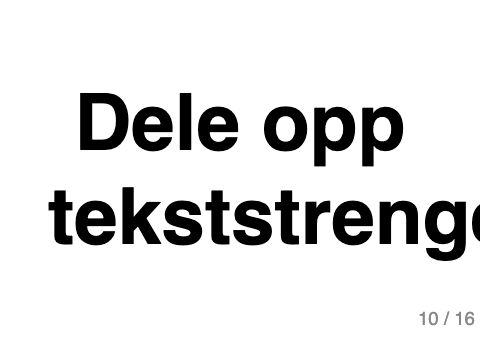

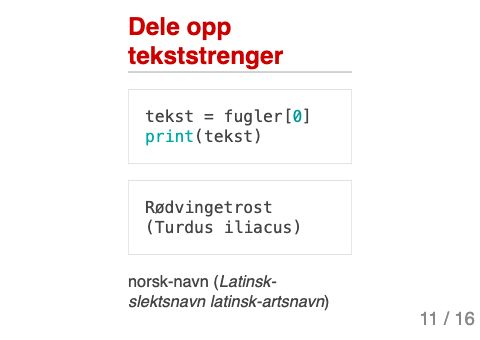

</div>

Vi ønsker å dele denne tekststrengen opp slik at vi får ut både det norske navnet
og det latinske navnet.

En god strategi er å dele tekststrengen opp i en liste over ord.
Det gjør vi med funksjonen `.split()`.

In [22]:
parts = tekst.split()
print(parts)

['Gråtrost', '(Turdus', 'pilaris)']


Vi ser her at fordi det er to mellomrom deles teksten i tre.
I denne listen har det norske navnet indeks 0,
slektsnavnet indeks 1 og artsnavnet indeks 2.

In [23]:
norsk_navn = parts[0]
tekst2 = parts[1]
tekst3 = parts[2]

print(norsk_navn)
print(tekst2)
print(tekst3)

Gråtrost
(Turdus
pilaris)


Vi ser at de latinske delene fortsatt har parenteser henholdsvis foran og etter.
Disse kan vi fjerne ved hjelp av slicing:

In [24]:
slektsnavn = tekst2[1:]
artsnavn = tekst3[:-1]
latinsk_navn = slektsnavn + " " + artsnavn

print(slektsnavn)
print(artsnavn)
print(latinsk_navn)

Turdus
pilaris
Turdus pilaris


Her bruker vi altså to ideer sammen:

* `.split()` deler teksten i ord
* slicing fjerner parentesene rundt de latinske delene

Det er ofte slik i programmering at flere enkle verktøy brukes sammen
for å løse en litt større oppgave.

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Oppgave: oppdeling av strenger

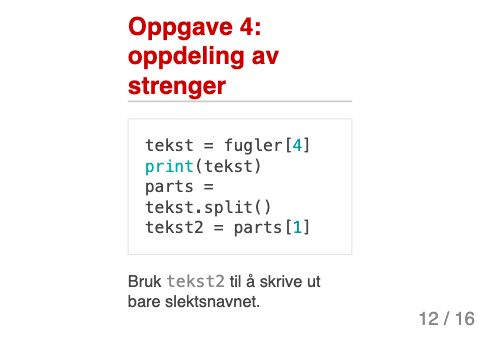

</div>

## Bruk av oppdeling av strenger på hele filen

Nå vil vi bruke den samme framgangsmåten på alle observasjonene i filen.
Da lager vi noen tomme lister som vi fyller opp etter hvert.

In [25]:
norske_navn = []
slektsnavn_liste = []
latinske_navn = []

i = 0
while i < len(fugler):
    tekst = fugler[i]
    parts = tekst.split()

    norsk_navn = parts[0]
    tekst2 = parts[1]
    tekst3 = parts[2]
    slektsnavn = tekst2[1:]
    artsnavn = tekst3[:-1]
    latinsk_navn = slektsnavn + " " + artsnavn

    norske_navn.append(norsk_navn)
    slektsnavn_liste.append(slektsnavn)
    latinske_navn.append(latinsk_navn)

    i = i + 1

print(norske_navn)
print(slektsnavn_liste)
print(latinske_navn)

['Rødvingetrost', 'Gråtrost', 'Blåmeis', 'Svarttrost', 'Bokfink', 'Kjøttmeis', 'Rødstrupe', 'Gransanger']
['Turdus', 'Turdus', 'Cyanistes', 'Turdus', 'Fringilla', 'Parus', 'Erithacus', 'Phylloscopus']
['Turdus iliacus', 'Turdus pilaris', 'Cyanistes caeruleus', 'Turdus merula', 'Fringilla coelebs', 'Parus major', 'Erithacus rubecula', 'Phylloscopus collybita']


Nå har vi gjort om en tekstkolonne som er lett å lese for mennesker
til flere lister som er lettere å analysere videre i Python.

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* f-strenger

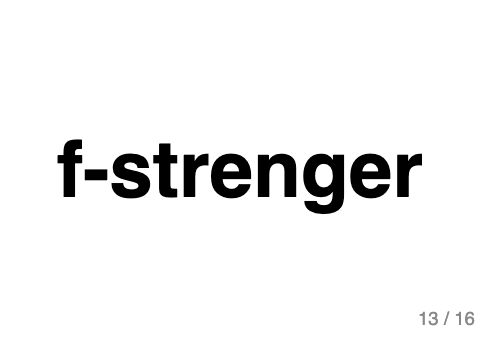

</div>

## Skrive ut tekst og variabler

Nå har vi renset artsnavnene fra observasjonsfilen.
Da ønsker vi å skrive ut resultatene på en måte som er lett å lese.

Vi starter med den første observasjonen:

In [26]:
norsk_navn = norske_navn[0]
latinsk_navn = latinske_navn[0]
antall_fugl = antall[0]
sted = steder[0]

print(norsk_navn)
print(latinsk_navn)
print(antall_fugl)
print(sted)

Rødvingetrost
Turdus iliacus
3
Nordmyra


Hvis vi vil kombinere tekst og variabler i én setning har vi hittil
gjort det på følgende måte:

In [27]:
print("På", sted, "observerte vi", antall_fugl, norsk_navn)

På Nordmyra observerte vi 3 Rødvingetrost


Det finnes også en annen, mye brukt måte å skrive ut slike kombinasjoner.
Den heter f-strenger.
Vi starter med en kort variant:

In [28]:
print(f"På {sted} observerte vi {antall_fugl} {norsk_navn}.")

På Nordmyra observerte vi 3 Rødvingetrost.


Og så kan vi lett utvide setningen:

In [29]:
print(f"På {sted} observerte vi {antall_fugl} {norsk_navn} med Latinsk navn {latinsk_navn}.")

På Nordmyra observerte vi 3 Rødvingetrost med Latinsk navn Turdus iliacus.


Merk:
* f-strengen defineres ved at det står en `f` før den første parentesen
* Det er bare et sett med parentes (en 'åpen' og en 'slutt')
* ingen pluss tegn eller kommaer
* variablen settes mellom `{` og `}`, som på norsk heter 'krøllparentes' (eller 'klammeparentes'), på engelsk 'curly brackets'
  * på en MAC er disse tastene `shift-alt-8` og `shift-alt-9`
  * på en PC er det `AltGr-7` og `AltGr-0`

Fordelen med metoden er at vi ikke trenger å tenke på om variabelen er en streng eller int/float.

Noe annet vi kan gjøre her er å regne inne i parentesene:

In [30]:
gjennomsnitt_antall = sum(antall) / len(antall)
print(f"Gjennomsnittlig antall individer per observasjon er {gjennomsnitt_antall}.")

Gjennomsnittlig antall individer per observasjon er 2.5.


Nå kan vi begynne å svare på spørsmålet vårt om genus `Turdus`:

In [31]:
turdus_observasjoner = slektsnavn_liste.count("Turdus")
print(f"Turdus forekommer i {turdus_observasjoner} av {len(slektsnavn_liste)} observasjoner.")

Turdus forekommer i 3 av 8 observasjoner.


f-strenger gir mye fleksibilitet og er mest brukt i Python kode.
Vi anbefaler dere å bli godt kjent med denne type streng.
Men det er ikke feil bruke den metoden vi så først.

Vi kan bruke `round()` om vi vil bestemme antall desimaler:

In [32]:
gjennomsnitt_antall = sum(antall) / len(antall)
print(f"Gjennomsnittlig antall individer per observasjon er {round(gjennomsnitt_antall, 1)}.")

Gjennomsnittlig antall individer per observasjon er 2.5.


Vi kan oppnå samme avrunding med hjelp av såkalte *formatting modifiers*:

In [33]:
andel_turdus = 100 * turdus_observasjoner / len(slektsnavn_liste)
print(f"Turdus utgjør {andel_turdus:.1f}% av observasjonene.")
print(f"Turdus utgjør {andel_turdus:.2f}% av observasjonene.")

Turdus utgjør 37.5% av observasjonene.
Turdus utgjør 37.50% av observasjonene.


Her blir variabelen fulgt av en kolon `:` og `.1f` eller `.2f`.
Dette indikerer formattering som float avrundet til henholdsvis 1 eller 2 desimaler.

## Ferdig program

Nå kan vi samle alt i ett program som går fra csv-filen til svaret på spørsmålet vårt:

In [34]:
import pandas as pd

data = pd.read_csv("species_observations.csv")

fugler = list(data["fugl"])
slektsnavn_liste = []

i = 0
while i < len(fugler):
    tekst = fugler[i]
    parts = tekst.split()
    tekst2 = parts[1]
    slektsnavn = tekst2[1:]

    slektsnavn_liste.append(slektsnavn)
    i = i + 1

turdus_observasjoner = slektsnavn_liste.count("Turdus")
andel_turdus = 100 * turdus_observasjoner / len(slektsnavn_liste)

print(f"Turdus utgjør {andel_turdus:.2f}% av observasjonene.")

Turdus utgjør 37.50% av observasjonene.


Da har vi fått svar på spørsmålet:
"Hvor stor andel av observasjonene er fugl av genus `Turdus`?"

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Skrive tekst i Markdown

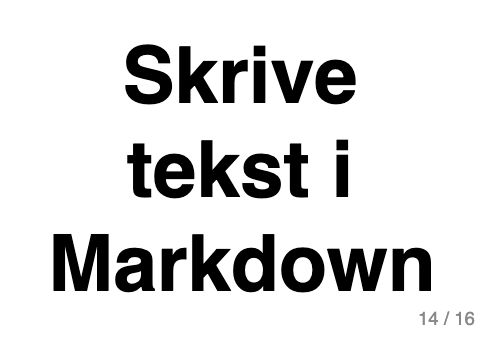

</div>

## Skive tekst i Markdown

Så langt vi skrevet mye kode og av og til et tekstsvar i Jupyter Notebook.
Når man skriver tekst bruker man en såkalt 'Markdown celle'.
*Markdown* er et eget språk som vi skal se nærmere på nå.

Markdown brukes ikke bare i Jupyter Notebook, det er godt mulig
du får bruk for det andre steder også etterhvert.

Vi starter i en ny notebook og gjør først om den første celle
til en Markdown celle

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Gjøre om en celle til en Markdown celle

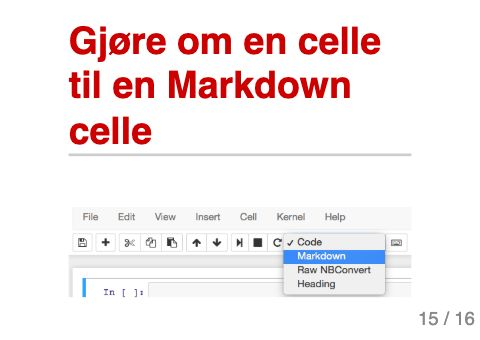

</div>

Nå kan vi skrive vanlig tekst.

<div class="alert alert-block alert-info">
Be studentene om en tekst du skal skrive, gjerne to-tre setninger.
</div>

Etter at vi har 'kjørt' cellen ser vi resultatet i notebook.

For å bruke skråskrift setter vi en stjerne `*` foran og bak den teksten
vi vil at er i skråskrift.
For fet skrift bruker vi to stjerner foran og bak.

<div class="alert alert-block alert-info">
Gjør om et ord til skråskrift og et til fet skrift, og vis resultatet.
</div>

Overskrifter gjøres ved hjelp av `#` symbolet.

<div class="alert alert-block alert-info">
Legg til et overskrift med en `#` og et underoverskrift med `##`. Vis eventuelt at man kan bruke flere, opp til 6, `#`.

VIKTIG det MÅ være et mellomrom etter `#`, hvis hva som skjer om det ikke er der.
</div>

For kulepunkter brukes en stjerne, et mellomrom og så teksten.

<div class="alert alert-block alert-info">
Be studenten om deres favorittfarge og lag en liste av det med hjelp av kulepunkter.
</div>

<div class="alert alert-block alert-info">
Be studentene nå gjennomføre Markdown Tutorial, lenke er på slide.
Lenke til CheatSheet er på Canvas under modulen 'Generell kursinformasjon'.
</div>

<div class="alert alert-block alert-warning">

<h2>Vis lysbilde(r):</h2>

* Oppgave: øve med Markdown

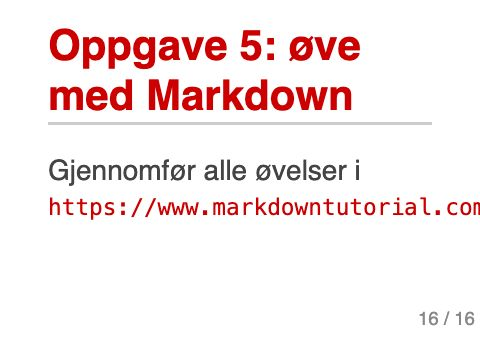

</div>